# Python程序设计与数据处理 · Class 3 作业

**主题：** 收益率的分布、累计收益与最大回撤（可视化）
**数据：** `datasets/000001.csv` — 上证综指日度行情，样本区间 **1995-01 至 2026-09**
（8,737 个交易日全样本；课堂分析与习题使用 1995 年以来的 7,708 个交易日、381 个月度观测）

> 5 道习题均附代码与运行结果；作图结果同时保存到 `images/` 目录。

## 准备工作｜构造课堂数据

按课堂流程准备三张表：日度 `data_new`、月度 `Month_data`、年度 `Year_data`，
并计算累计收益与回撤。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import seaborn as sns

%matplotlib inline

In [2]:
# 读取上证综指日度数据，日期设为索引
data = pd.read_csv('datasets/000001.csv')
data['Day'] = pd.to_datetime(data['Day'], format='%Y/%m/%d')
data.set_index('Day', inplace=True)

# 课堂样本：1995-01 至 2026-09
data_new = data['1995-01':'2026-09'].copy()
data_new['Close'] = pd.to_numeric(data_new['Close'])
data_new['Preclose'] = pd.to_numeric(data_new['Preclose'])
data_new['Raw_return'] = data_new['Close'] / data_new['Preclose'] - 1
data_new.head()

,Preclose,Open,Highest,Lowest,Close,Raw_return
Day,,,,,,
1995-01-03,647.87,637.72,647.71,630.53,639.88,-0.012333
1995-01-04,639.88,641.90,655.51,638.86,653.81,0.021770
1995-01-05,653.81,655.38,657.52,645.81,646.89,-0.010584
1995-01-06,646.89,642.75,643.89,636.33,640.76,-0.009476
1995-01-09,640.76,637.52,637.55,625.04,626.00,-0.023035


In [3]:
# 月度 / 年度收益率：月（年）内日收益率连乘
Month_data = data_new.resample('ME')['Raw_return'].apply(lambda x: np.prod(1 + x) - 1).to_frame(name='Ret')
Year_data = data_new.resample('YE')['Raw_return'].apply(lambda x: np.prod(1 + x) - 1).to_frame(name='Ret')

# 月度辅助字段
Month_data['Year'] = Month_data.index.year
Month_data['Month'] = Month_data.index.month
Month_data['Month_name'] = Month_data.index.strftime('%b')
Month_data['Decade'] = (Month_data['Year'] // 10) * 10

Month_data.head()

,Ret,Year,Month,Month_name,Decade
Day,,,,,
1995-01-31,-0.131631,1995,1,Jan,1990
1995-02-28,-0.023694,1995,2,Feb,1990
1995-03-31,0.177803,1995,3,Mar,1990
1995-04-30,-0.103552,1995,4,Apr,1990
1995-05-31,0.207922,1995,5,May,1990


In [4]:
# 累计收益与回撤
wealth = (1 + data_new['Raw_return']).cumprod()          # 净值曲线（起点=1）
data_new['Cum_return'] = wealth - 1                       # 累计收益率
data_new['Peak'] = wealth.cummax()                        # 历史最高净值
data_new['Drawdown'] = wealth / data_new['Peak'] - 1      # 回撤（负值）

data_new[['Close', 'Raw_return', 'Cum_return', 'Drawdown']].head()

,Close,Raw_return,Cum_return,Drawdown
Day,,,,
1995-01-03,639.88,-0.012333,-0.012333,0.000000
1995-01-04,653.81,0.021770,0.009169,0.000000
1995-01-05,646.89,-0.010584,-0.001513,-0.010584
1995-01-06,640.76,-0.009476,-0.010974,-0.019960
1995-01-09,626.00,-0.023035,-0.033757,-0.042535


## 习题 1｜用月度收益重建 2008 年年度收益

用 `Month_data` 的月度收益重建 2008 年的年度收益，并验证它与 `Year_data` 中 2008 年的值是否一致（`np.allclose`）。

In [5]:
# 月度收益连乘：12 个月的 (1+r) 相乘
ret_2008_from_month = np.prod(1 + Month_data.loc['2008', 'Ret']) - 1
# Year_data 中 2008 年的年度收益
ret_2008_from_year = Year_data.loc['2008-12-31', 'Ret']

print('月度连乘重建的2008年收益:', ret_2008_from_month)
print('Year_data中的2008年收益:', ret_2008_from_year)
print('np.allclose:', np.allclose(ret_2008_from_month, ret_2008_from_year))
print('绝对差异:', abs(ret_2008_from_month - ret_2008_from_year))

月度连乘重建的2008年收益: -0.6539410364986811
Year_data中的2008年收益: -0.6539410364986822
np.allclose: True
绝对差异: 1.1102230246251565e-15


**结论：** 2008 年上证综指全年收益 **-65.39%**，两法结果一致（`np.allclose = True`，
差异仅 1.1×10⁻¹⁵ 的浮点舍入）。原因很直接：年度收益就是当年 12 个月 (1+r) 的连乘，
而 `Month_data` 的月度收益又由日内收益率连乘得到——连乘可逆地"拼"回去。

## 习题 2｜累计收益曲线

画出上证指数的累计收益曲线（`Cum_return`），y 轴用百分比格式，加一条 y=0 的灰色虚线。

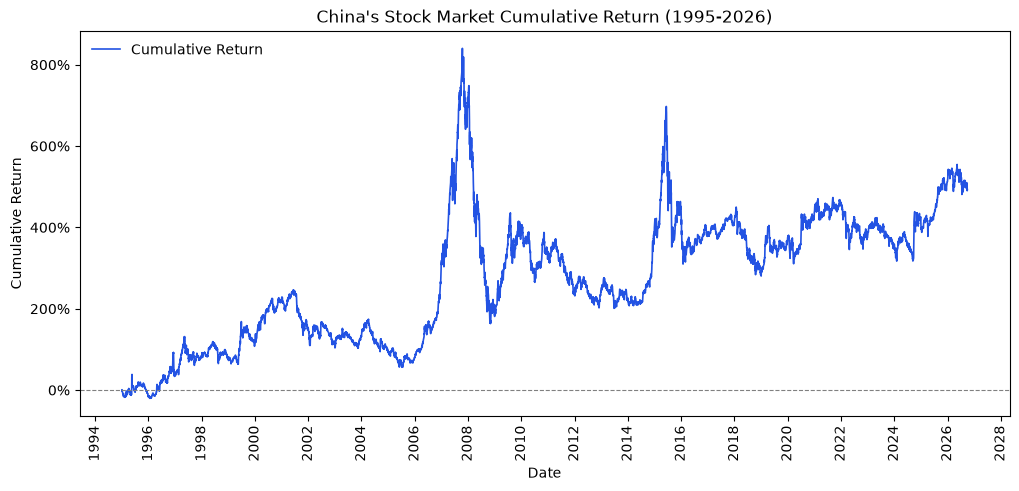

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    data_new.index,
    data_new['Cum_return'],
    color='#2353E3',
    linewidth=1.2,
    label='Cumulative Return'
)

ax.set_title("China's Stock Market Cumulative Return (1995-2026)")
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=90)

ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
ax.legend(loc='upper left', frameon=False)

fig.savefig('images/Cumulative_return.pdf', bbox_inches='tight')
plt.show();

**结果：** 截至 2026-09-30，1995 年以来累计收益 **+493.05%**（净值约 5.93 倍）。
曲线最陡的上涨出现在 2006-2007 年，2008 年与 2015 年后出现明显回撤段。

## 习题 3｜回撤图

画回撤图（`Drawdown` 为负值），用 `fill_between` 填充到 0 轴，填充色用红色、透明度 0.5。

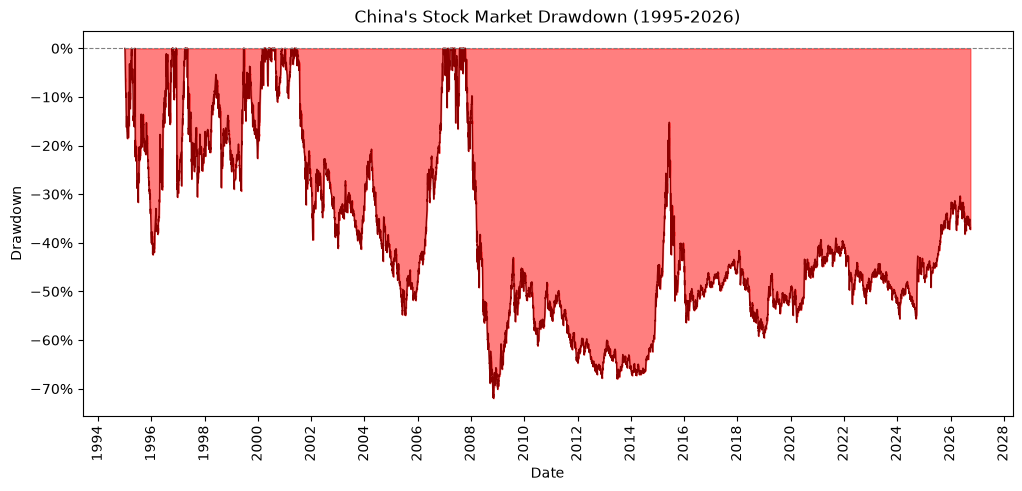

In [7]:
# 回撤：当前净值 / 历史最高净值 - 1（负值）
drawdown = data_new['Drawdown']

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(drawdown.index, drawdown, color='darkred', linewidth=1)
ax.fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.5)

ax.set_title("China's Stock Market Drawdown (1995-2026)")
ax.set_xlabel('Date')
ax.set_ylabel('Drawdown')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=90)

ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)

fig.savefig('images/Drawdown.pdf', bbox_inches='tight')
plt.show();

In [8]:
# 最大回撤及其发生日期
print('最大回撤:', f'{drawdown.min():.2%}')
print('发生日期:', drawdown.idxmin().date())
print('回撤中位数:', f'{drawdown.median():.2%}')

最大回撤: -71.98%
发生日期: 2008-11-04
回撤中位数: -44.27%


**结果：** 样本期内最大回撤 **-71.98%**，发生在 **2008-11-04**（全球金融危机底部）；
回撤中位数为 -44.27%——意味着有一半时间市场处于"从前期高点下跌超过四成"的状态，
直观解释了"股票长期收益高、但很少有人拿得住"的现象。

## 习题 4｜月度收益分布

画月度收益的直方图，`bins=40`，加 KDE 曲线，加一条均值位置的黑色竖虚线。

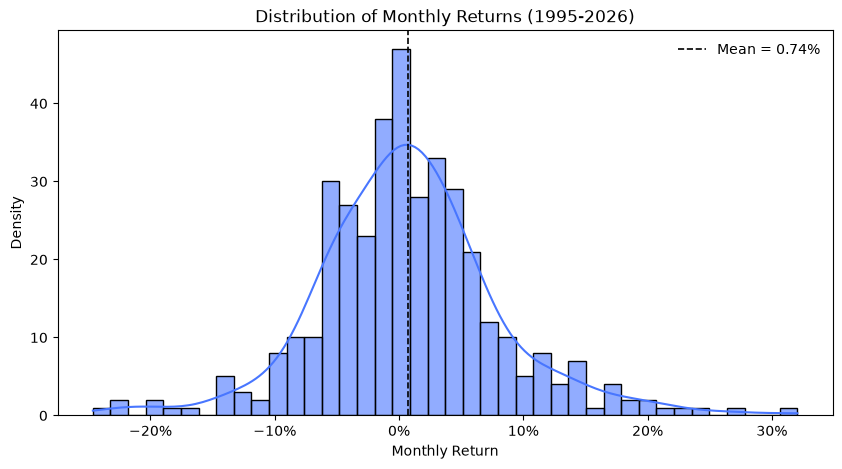

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    Month_data['Ret'],
    bins=40,
    kde=True,
    color='#4876FF',
    alpha=0.6,
    ax=ax
)

mean_ret = Month_data['Ret'].mean()
ax.axvline(mean_ret, color='black', linestyle='--', linewidth=1.2,
           label=f'Mean = {mean_ret:.2%}')

ax.set_title("Distribution of Monthly Returns (1995-2026)")
ax.set_xlabel('Monthly Return')
ax.set_ylabel('Density')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(frameon=False)

fig.savefig('images/Monthly_return_hist_kde.pdf', bbox_inches='tight')
plt.show();

**结果：** 381 个月的月度收益均值 **+0.74%**，标准差 **7.41%**，偏度 **0.33**（轻微右偏），
区间 [-24.63%, +32.06%]。分布中间尖、两侧厚尾——极端月份虽少，但对长期复利影响很大。

## 习题 5｜按日历月份的箱线图

按月份画箱线图（x 轴为月份缩写，y 轴为月收益）。

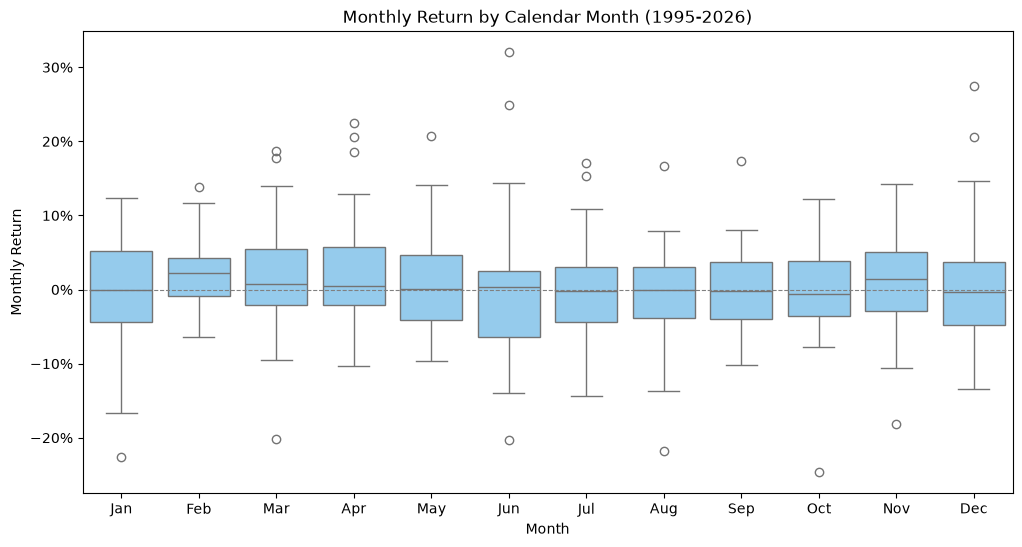

In [10]:
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=Month_data,
    x='Month_name',
    y='Ret',
    order=month_order,
    color='#87CEFA',
    ax=ax
)

ax.set_title("Monthly Return by Calendar Month (1995-2026)")
ax.set_xlabel('Month')
ax.set_ylabel('Monthly Return')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)

fig.savefig('images/Monthly_return_boxplot.pdf', bbox_inches='tight')
plt.show();

In [11]:
# 各月均值排序，观察是否存在"月份效应"
month_mean = Month_data.groupby('Month_name')['Ret'].mean().reindex(month_order)
print(month_mean.map(lambda x: f'{x:.2%}'))

Month_name
Jan    -0.56%
Feb     2.33%
Mar     1.91%
Apr     2.50%
May     0.95%
Jun     0.08%
Jul     0.52%
Aug    -0.96%
Sep     0.14%
Oct     0.21%
Nov     0.85%
Dec     0.88%
Name: Ret, dtype: str


**结果：** 各月均值差异明显：**4 月最高（+2.50%）**、**8 月最低（-0.96%）**，
但箱体大量重叠、离群点很多——说明"月份效应"在这个样本里并不稳定，
单靠日历月份做择时并不可靠（31-32 个观测/月，样本量也很有限）。